In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import ImageProcessing as ip

# 1. Load original image and convert to HSV

In [2]:
image = ip.LoadImage("Juice.jpg")
rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

## Size: w =4080 h =3060

## Channels: 3

## Format: uint8

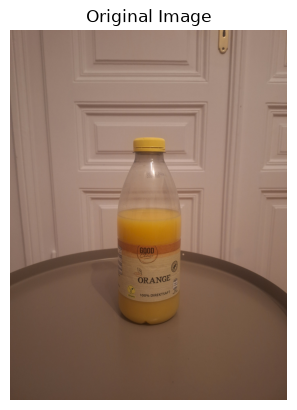

In [3]:
plt.imshow(rgb_image)
plt.title("Original Image")
plt.axis('off')  
plt.show()

In [4]:
hsv_image = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

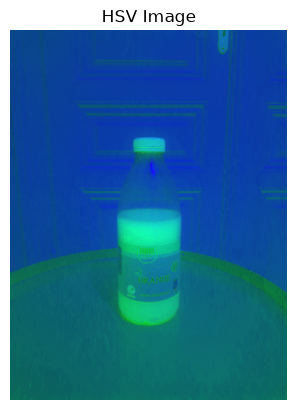

In [5]:
plt.imshow(hsv_image)  
plt.title("HSV Image")
plt.axis('off')  
plt.show()

# 2. Point Operation - Histogram Equalization

In [6]:
#only equalize brightness channel to be able to convert back to colours later
hsv_image[:, :, 2] = cv2.equalizeHist(hsv_image[:, :, 2])

equalized_image = cv2.cvtColor(hsv_image, cv2.COLOR_HSV2BGR)
rgb_equalized_image = cv2.cvtColor(hsv_image, cv2.COLOR_HSV2RGB)
rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

comparison = np.hstack((rgb_image, rgb_equalized_image))

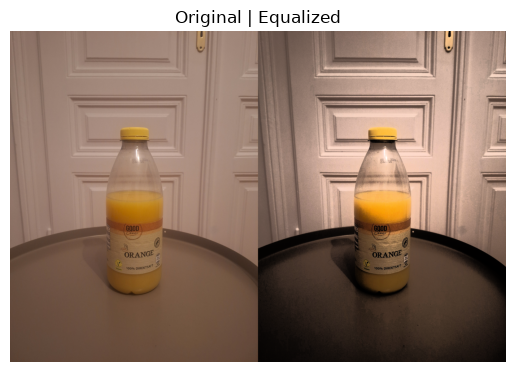

In [7]:
plt.imshow(comparison)
plt.title("Original | Equalized")
plt.axis('off')
plt.show()

# 3. Noise reduction - Gaussian Blur

In [8]:
gaussian_image = cv2.GaussianBlur(equalized_image, (5, 5), 0)
rgb_gaussian_image = cv2.cvtColor(gaussian_image, cv2.COLOR_BGR2RGB)

comparison = np.hstack((rgb_image, rgb_gaussian_image))

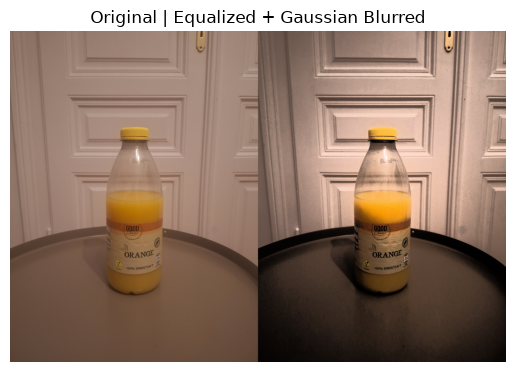

In [9]:
plt.imshow(comparison)
plt.title("Original | Equalized + Gaussian Blurred")
plt.axis('off')
plt.show()

# 4. Segmentation and Cleanup

In [10]:
hsv_gaussian_image = cv2.cvtColor(gaussian_image, cv2.COLOR_BGR2HSV)
threshold1, saturation_mask = cv2.threshold(hsv_gaussian_image[:, :, 1], 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
threshold2, brightness_mask = cv2.threshold(hsv_gaussian_image[:, :, 2], 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

kernel = np.ones((5, 5), np.uint8)
gaussian_image[(saturation_mask == 0)] = 150
eroded_image = cv2.erode(gaussian_image, kernel, iterations=1)
result_image = cv2.cvtColor(eroded_image, cv2.COLOR_BGR2RGB)

comparison = np.hstack((rgb_image, result_image))

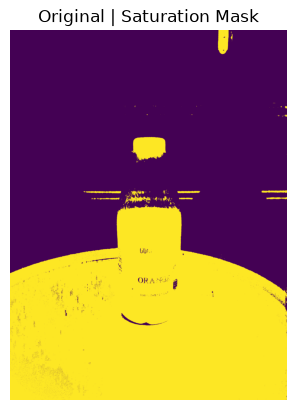

In [11]:
plt.imshow(saturation_mask)
plt.title("Original | Saturation Mask")
plt.axis('off')
plt.show()

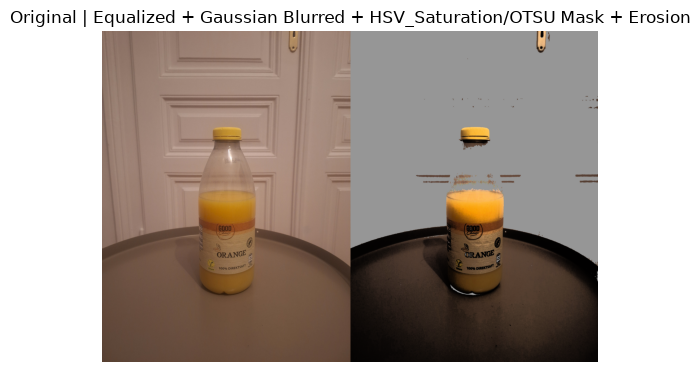

In [12]:
plt.imshow(comparison)
plt.title("Original | Equalized + Gaussian Blurred + HSV_Saturation/OTSU Mask + Erosion")
plt.axis('off')
plt.show()